# 1.6 — Resumen de la ingesta

Esta libreta resume las libretas de ingesta `1.0` a `1.5`. Para cada fuente
responde tres preguntas:

1. **¿Cuántos datos llegaron?** La tabla que dejó la ingesta.
2. **¿Son válidos?** Cada fila se revisa con un esquema **pydantic**: una
   plantilla que dice qué columnas debe tener la fila, de qué tipo y en qué
   rango (por ejemplo, la humedad entre 0 y 100 %).
3. **¿Llegaron completos a la tabla procesada?** La tabla final de
   Hermosillo debe tener los **72 meses** de 2015 a 2020.

| Fuente | Libreta | Qué trae |
|--------|---------|----------|
| Temperatura SMN | `1.0` | Temperatura mensual de cada estación del país |
| Open-Meteo | `1.1` | Temperatura y humedad diarias de Hermosillo |
| Sequía | `1.2` | Categoría de sequía de cada municipio de Sonora, cada quincena |
| Marginación | `1.3` | Índice de marginación de los municipios de Sonora |
| Calidad del aire | `1.4` | PM2.5, PM10 y ozono cada hora (RUOA-ERNO) |
| Salud (IRA) | `1.5` | Casos de infecciones respiratorias por semana y unidad médica |
| Catálogo CLUES | `1.5` | Ubicación de las unidades médicas |

## Preparación

In [1]:
from pathlib import Path
import sys

# La libreta está en notebooks/01_ingesta/: subimos dos carpetas para llegar al proyecto
sys.path.append(str(Path.cwd().parent.parent))

import matplotlib.pyplot as plt
import pandas as pd

# Carpetas de datos del proyecto
from sonora_health_climate_eda.config import (
    EXTERNAL_DATA_DIR, FIGURES_DIR, INTERIM_DATA_DIR, PROCESSED_DATA_DIR, RAW_DATA_DIR,
)
# Esquemas pydantic (uno por fuente) y la función que valida una tabla con ellos
from sonora_health_climate_eda.schemas import (
    AireHorarioSchema, CluesHermosilloSchema, InfeccionesRespiratoriasSonoraSchema,
    MarginacionMunicipalSchema, OpenMeteoDiarioSchema, SequiaSonoraSchema,
    TemperaturaEstacionSchema, validate_dataframe,
)

**Cómo se valida:** `validate_dataframe(tabla, esquema)` revisa la tabla
fila por fila y devuelve dos tablas: las filas **válidas** y los
**errores** (qué fila falló, en qué campo y por qué).

## 1. Temperatura SMN (libreta `1.0`)

Un CSV por mes con la temperatura media de cada estación del país. El
esquema revisa que la temperatura esté entre −50 y 65 °C y que las
coordenadas sean válidas.

In [2]:
temperatura = pd.read_csv(PROCESSED_DATA_DIR / "temperaturas_nacional_2015_2020.csv")
temperatura_ok, temperatura_err = validate_dataframe(temperatura, TemperaturaEstacionSchema)
clima = pd.read_parquet(PROCESSED_DATA_DIR / "climate_hermosillo.parquet")

print(f"Llegaron:   {len(temperatura):,} filas (estación × mes)")
print(f"Válidas:    {len(temperatura_ok):,}   Rechazadas: {len(temperatura_err)}")
print(f"Procesado:  {clima['fecha_mes'].nunique()} de 72 meses de Hermosillo")

# Así quedó la tabla de ingesta que usa el procesamiento
temperatura.head()

Llegaron:   77,027 filas (estación × mes)
Válidas:    77,027   Rechazadas: 0
Procesado:  72 de 72 meses de Hermosillo


,lon,lat,clave,edo,est,temp_promedio,archivo_origen,anio,mes,fecha
0,-89.68,20.65,ABAYC,YUC,"Abalá, Yuc.",19.8,201501010000TMed.csv,2015,1,2015-01-01
1,-101.54,20.45,ABSGJ,GTO,"Abasolo, Gto.",17.4,201501010000TMed.csv,2015,1,2015-01-01
2,-98.39,24.07,ABSTP,TAMP,"Abasolo, Tamps.",14.4,201501010000TMed.csv,2015,1,2015-01-01
3,-92.80,16.55,ACACP,CHIS,"Acala, Chis.",21.8,201501010000TMed.csv,2015,1,2015-01-01
4,-99.91,16.85,ACAGR,GRO,"Acapulco, Gro.",26.8,201501010000TMed.csv,2015,1,2015-01-01


## 2. Open-Meteo (libreta `1.1`)

Una fila por día de 1991 a 2020. El esquema revisa rangos de temperatura,
que la humedad esté entre 0 y 100 % y que la máxima no sea menor que la
mínima.

In [3]:
openmeteo = pd.read_csv(RAW_DATA_DIR / "openmeteo_hermosillo_daily_1991_2020.csv")
openmeteo_ok, openmeteo_err = validate_dataframe(openmeteo, OpenMeteoDiarioSchema)
calor = pd.read_parquet(PROCESSED_DATA_DIR / "openmeteo_hermosillo_monthly.parquet")

print(f"Llegaron:   {len(openmeteo):,} días")
print(f"Válidas:    {len(openmeteo_ok):,}   Rechazadas: {len(openmeteo_err)}")
print(f"Procesado:  {calor['fecha_mes'].nunique()} de 72 meses de Hermosillo")

# Así quedó la tabla de ingesta que usa el procesamiento
openmeteo.head()

Llegaron:   10,958 días
Válidas:    10,958   Rechazadas: 0
Procesado:  72 de 72 meses de Hermosillo


,fecha,tmax_c,tmin_c,humedad_rel_pct
0,1991-01-01,23.1,9.1,75
1,1991-01-02,24.4,9.4,70
2,1991-01-03,25.8,12.3,67
3,1991-01-04,21.8,13.8,71
4,1991-01-05,18.9,14.6,91


## 3. Sequía (libreta `1.2`)

La ingesta deja un CSV por año con cada municipio de Sonora y quincena. El
esquema revisa las claves y que la severidad vaya de 0 (sin sequía) a 5
(sequía excepcional).

In [4]:
archivos = sorted((INTERIM_DATA_DIR / "sonora_sequia").glob("sonora_sequia_*.csv"))
sequia = pd.concat([pd.read_csv(f) for f in archivos])
sequia_ok, sequia_err = validate_dataframe(sequia, SequiaSonoraSchema)
sequia_hmo = pd.read_parquet(PROCESSED_DATA_DIR / "drought_hermosillo.parquet")

print(f"Llegaron:   {len(sequia):,} filas (municipio × quincena)")
print(f"Válidas:    {len(sequia_ok):,}   Rechazadas: {len(sequia_err)}")
print(f"Procesado:  {sequia_hmo['fecha_mes'].nunique()} de 72 meses de Hermosillo")

# Así quedó la tabla de ingesta que usa el procesamiento
sequia.head()

Llegaron:   10,368 filas (municipio × quincena)
Válidas:    10,368   Rechazadas: 0
Procesado:  72 de 72 meses de Hermosillo


,CVE_CONCATENADA,CVE_ENT,CVE_MUN,fecha,categoria_sequia,Anio,severidad_num
0,26001,26,1,2015-01-15,NaN,2015,0
1,26002,26,2,2015-01-15,D0,2015,1
2,26003,26,3,2015-01-15,D0,2015,1
3,26004,26,4,2015-01-15,D0,2015,1
4,26005,26,5,2015-01-15,D0,2015,1


## 4. Marginación (libreta `1.3`)

Los 72 municipios de Sonora en 2015 y en 2020. El esquema revisa que los
indicadores sean porcentajes y que el grado sea una de las cinco
categorías oficiales (Muy bajo … Muy alto).

In [5]:
marginacion = pd.concat([
    pd.read_csv(INTERIM_DATA_DIR / "marginacion" / "marginacion_municipal_2015.csv"),
    pd.read_csv(INTERIM_DATA_DIR / "marginacion" / "marginacion_municipal_2020.csv"),
])
marginacion_ok, marginacion_err = validate_dataframe(marginacion, MarginacionMunicipalSchema)
marginacion_hmo = pd.read_parquet(PROCESSED_DATA_DIR / "marginacion_hermosillo.parquet")

print(f"Llegaron:   {len(marginacion)} filas (municipio × año)")
print(f"Válidas:    {len(marginacion_ok)}   Rechazadas: {len(marginacion_err)}")
print(f"Procesado:  {marginacion_hmo['fecha_mes'].nunique()} de 72 meses de Hermosillo")

# Así quedó la tabla de ingesta que usa el procesamiento
marginacion.head()

Llegaron:   144 filas (municipio × año)
Válidas:    144   Rechazadas: 0
Procesado:  72 de 72 meses de Hermosillo


,CVE_ENT,NOM_ENT,CVE_MUN,NOM_MUN,POB_TOT,ANALF,SBASC,OVSDE,OVSEE,OVSAE,OVPT,VHAC,PL.5000,PO2SM,IM,GM,IMN
0,26,Sonora,26001,Aconchi,2756,3.539382,43.091451,1.705370,0.507983,1.197388,1.017072,28.679245,100.000000,18.835979,48.634835,Muy bajo,0.893269
1,26,Sonora,26002,Agua Prieta,82918,1.534487,32.588882,0.228703,1.764507,1.027414,1.353658,27.974875,2.380665,33.255636,50.349235,Muy bajo,0.924757
2,26,Sonora,26003,Alamos,25694,9.522021,51.355265,7.674292,3.708465,7.891458,9.942318,35.277178,63.847591,47.317780,44.877431,Medio,0.824257
3,26,Sonora,26004,Altar,9578,3.858824,42.184192,1.046025,0.356021,2.447699,1.434855,35.170178,12.403425,36.612702,49.273356,Muy bajo,0.904997
4,26,Sonora,26005,Arivechi,1163,3.037120,52.578475,1.122625,18.652850,0.259067,3.454231,22.527473,100.000000,14.191419,45.127730,Medio,0.828854


> La capa de marginación **por colonia** (para la libreta `3.6`) se genera
> en la sección "Colonias 2020" de la `1.3`, después de bajar el ZIP de
> CONAPO con el navegador.

## 5. Calidad del aire (libreta `1.4`)

Una fila por hora. Cada medición trae una **bandera**: `OK`, `BDL` (debajo
del límite de detección), `OR` (fuera de rango) u `OS` (equipo fuera de
servicio). El esquema revisa que la bandera exista y concuerde con el
valor.

In [6]:
aire = pd.read_csv(INTERIM_DATA_DIR / "aire" / "aire_hermosillo_horario.csv")
aire_ok, aire_err = validate_dataframe(aire, AireHorarioSchema)
aire_hmo = pd.read_csv(PROCESSED_DATA_DIR / "aire" / "aire_hermosillo_mensual.csv")

print(f"Llegaron:   {len(aire):,} horas")
print(f"Válidas:    {len(aire_ok):,}   Rechazadas: {len(aire_err)}")
print(f"Procesado:  {aire_hmo['fecha_mes'].nunique()} de 72 meses de Hermosillo")

# Así quedó la tabla de ingesta que usa el procesamiento
aire.head()

Llegaron:   52,608 horas
Válidas:    52,608   Rechazadas: 0
Procesado:  72 de 72 meses de Hermosillo


,fecha_hora,pm25_ugm3,pm25_bandera,pm10_ugm3,pm10_bandera,o3_ppb,o3_bandera
0,2015-01-01 00:00:00,NaN,OS,10.82,OK,29.23,OK
1,2015-01-01 01:00:00,NaN,OS,12.02,OK,22.82,OK
2,2015-01-01 02:00:00,NaN,OS,12.63,OK,27.72,OK
3,2015-01-01 03:00:00,NaN,OS,8.45,OK,35.84,OK
4,2015-01-01 04:00:00,NaN,OS,2.88,BDL,40.27,OK


## 6. Salud: infecciones respiratorias (libreta `1.5`)

Casos confirmados de IRA de todo Sonora, 2010–2020. El esquema revisa
municipio, año, semana (1 a 53) y que los casos no sean negativos. Son 1.7
millones de filas: **esta celda tarda alrededor de un minuto**.

In [7]:
salud = pd.read_csv(RAW_DATA_DIR / "salud" / "enf_resp_sonora_2010_2020.csv")
salud_ok, salud_err = validate_dataframe(salud, InfeccionesRespiratoriasSonoraSchema)
salud_hmo = pd.read_parquet(PROCESSED_DATA_DIR / "health_ira_monthly.parquet")

print(f"Llegaron:   {len(salud):,} filas")
print(f"Válidas:    {len(salud_ok):,}   Rechazadas: {len(salud_err)}")
print(f"Procesado:  {salud_hmo['fecha_mes'].nunique()} de 72 meses de Hermosillo")

# Así quedó la tabla de ingesta que usa el procesamiento
salud.head()

Llegaron:   1,732,444 filas
Válidas:    1,732,444   Rechazadas: 0
Procesado:  72 de 72 meses de Hermosillo


,clave_municipio,municipio,clave_entidad,anio,semana,genero,grupo_edad,clave_enfermedad,clues,casos
0,1,ACONCHI,26,2010,1,Masculino,De 00 años,"J00-J06, J20, J21 EXCEPTO J02.0 Y J03.0",SRIMB000021,1
1,1,ACONCHI,26,2010,1,Masculino,De 05 a 09 años,"J00-J06, J20, J21 EXCEPTO J02.0 Y J03.0",SRIMS000010,1
2,1,ACONCHI,26,2010,1,Femenino,De 15 a 19 años,"J00-J06, J20, J21 EXCEPTO J02.0 Y J03.0",SRIMB000021,1
3,1,ACONCHI,26,2010,1,Masculino,De 50 a 59 años,"J00-J06, J20, J21 EXCEPTO J02.0 Y J03.0",SRIMS000010,1
4,1,ACONCHI,26,2010,1,Femenino,De 50 a 59 años,"J00-J06, J20, J21 EXCEPTO J02.0 Y J03.0",SRIMS000010,1


## 7. Catálogo CLUES (libreta `1.5`)

Las unidades médicas de Hermosillo que reportaron casos, con su latitud y
longitud. El esquema revisa que **las coordenadas caigan en Sonora**.

In [8]:
clues = pd.read_csv(EXTERNAL_DATA_DIR / "clues" / "clues_hermosillo_ira.csv")
clues_ok, clues_err = validate_dataframe(clues, CluesHermosilloSchema)

print(f"Llegaron:   {len(clues)} unidades médicas")
print(f"Válidas:    {len(clues_ok)}   Rechazadas: {len(clues_err)}")

# ¿Cuáles se rechazaron?
display(clues.loc[clues_err["fila"], ["NOMBRE DE LA UNIDAD", "LATITUD", "LONGITUD"]])

# Así quedó la tabla de ingesta (68 columnas; aquí solo las principales)
clues[["CLUES", "NOMBRE DE LA INSTITUCION", "NOMBRE DE LA UNIDAD", "LATITUD", "LONGITUD"]].head()

Llegaron:   103 unidades médicas
Válidas:    86   Rechazadas: 17


,NOMBRE DE LA UNIDAD,LATITUD,LONGITUD
59,FARMACIAS BENAVIDES,NaN,NaN
68,FARMACIAS SIMILARES,19.369740,-99.165590
69,FARMACIAS SIMILARES,19.377367,-99.164197
70,FARMACIAS SIMILARES,19.362109,-99.143126
71,FARMACIAS SIMILARES,19.362109,-99.143126
72,FARMACIAS SIMILARES,19.368470,-99.142940
73,FARMACIAS SIMILARES,NaN,NaN
74,FARMACIAS SIMILARES,19.397880,-99.143824
75,FARMACIAS SIMILARES,19.379800,-99.138110
76,FARMACIAS SIMILARES,19.391285,-99.132553


,CLUES,NOMBRE DE LA INSTITUCION,NOMBRE DE LA UNIDAD,LATITUD,LONGITUD
0,SRIMB000890,SERVICIOS DE SALUD IMSS BIENESTAR,CENTRO AVANZADO DE ATENCIÓN PRIMARÍA A LA SALUD,29.099540,-110.975088
1,SRIMB000914,SERVICIOS DE SALUD IMSS BIENESTAR,HOSPITAL INFANTIL DEL ESTADO DE SONORA,29.116381,-110.971802
2,SRIMB000943,SERVICIOS DE SALUD IMSS BIENESTAR,CENTRO DE SALUD URBANO SANTA ISABEL,29.118303,-110.985380
3,SRIMB000955,SERVICIOS DE SALUD IMSS BIENESTAR,CENTRO DE SALUD URBANO CIUDAD DE LOS NIÑOS,29.006555,-110.921187
4,SRIMB000960,SERVICIOS DE SALUD IMSS BIENESTAR,CENTRO DE SALUD URBANO PRIMERO HERMOSILLO,29.129377,-110.997353


> **Hallazgo:** las 17 rechazadas son consultorios de farmacias privadas
> (16 Farmacias Similares, 1 Farmacias Benavides). Cuatro no tienen
> coordenadas y 13 están ubicadas en la **Ciudad de México** (latitud
> ≈ 19.4) aunque el catálogo diga Hermosillo. Por eso no se pueden ubicar
> en una colonia.
>
> **¿Por qué están mal?** El error viene del catálogo maestro DGIS, no de
> la ingesta: las 16 Similares fueron modificadas en lote el **07/07/2016**
> (*"actualización localidad y jurisdicción"*) y quedaron con las
> coordenadas del **domicilio corporativo de la cadena en CDMX**, aunque su
> domicilio declarado (calle, colonia, CP 83xxx) sí es de Hermosillo; a 4
> nunca se les capturó la coordenada. Todas siguen **en operación** y
> acumulan ~35.6 mil casos de IRA (1.6 % del total de Hermosillo). Es un
> problema nacional de la cadena: de 4,292 Farmacias Similares en el
> catálogo, ~29 % no tienen coordenadas y otras 275 traen coords de CDMX
> estando registradas en otros estados. Detalle en
> `references/salud/nota_calidad_clues_coordenadas.md`.

## Resumen

In [9]:
resumen = pd.DataFrame(
    [
        ["Temperatura SMN", len(temperatura), len(temperatura_ok), clima["fecha_mes"].nunique()],
        ["Open-Meteo", len(openmeteo), len(openmeteo_ok), calor["fecha_mes"].nunique()],
        ["Sequía", len(sequia), len(sequia_ok), sequia_hmo["fecha_mes"].nunique()],
        ["Marginación", len(marginacion), len(marginacion_ok), marginacion_hmo["fecha_mes"].nunique()],
        ["Calidad del aire", len(aire), len(aire_ok), aire_hmo["fecha_mes"].nunique()],
        ["Salud (IRA)", len(salud), len(salud_ok), salud_hmo["fecha_mes"].nunique()],
        ["Catálogo CLUES", len(clues), len(clues_ok), None],
    ],
    columns=["fuente", "filas que llegaron", "filas válidas", "meses en la tabla procesada"],
)
resumen["meses en la tabla procesada"] = resumen["meses en la tabla procesada"].astype("Int64")
resumen["% válidas"] = (100 * resumen["filas válidas"] / resumen["filas que llegaron"]).round(1)
resumen

,fuente,filas que llegaron,filas válidas,meses en la tabla procesada,% válidas
0,Temperatura SMN,77027,77027,72,100.0
1,Open-Meteo,10958,10958,72,100.0
2,Sequía,10368,10368,72,100.0
3,Marginación,144,144,72,100.0
4,Calidad del aire,52608,52608,72,100.0
5,Salud (IRA),1732444,1732444,72,100.0
6,Catálogo CLUES,103,86,<NA>,83.5


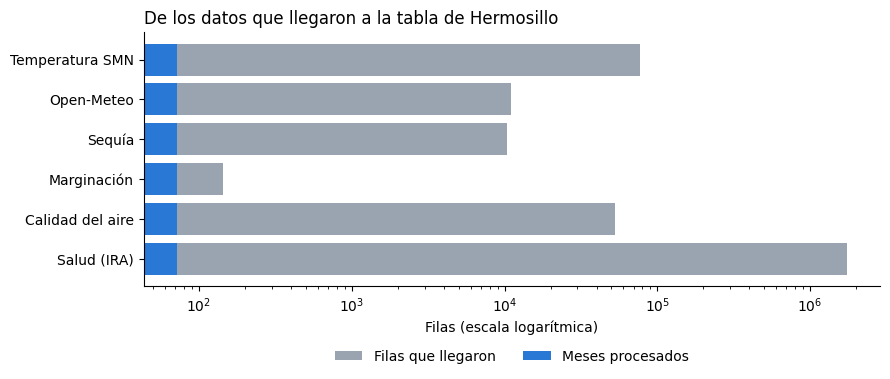

In [10]:
# Cada fuente empieza con miles o millones de filas y termina en 72 meses de Hermosillo
tabla = resumen.dropna(subset=["meses en la tabla procesada"])

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(tabla["fuente"], tabla["filas que llegaron"], color="#9aa4b1", label="Filas que llegaron")
ax.barh(tabla["fuente"], tabla["meses en la tabla procesada"], color="#2a78d6", label="Meses procesados")
ax.set_xscale("log")  # escala logarítmica: cada marca es 10 veces la anterior
ax.invert_yaxis()
ax.set_xlabel("Filas (escala logarítmica)")
ax.set_title("De los datos que llegaron a la tabla de Hermosillo", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "ingesta_raw_a_procesado.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusiones

- **Los datos son válidos.** Seis de las siete fuentes pasan su esquema
  pydantic al 100 %: más de 1.8 millones de filas revisadas.
- **Llegaron completos.** Todas las tablas procesadas tienen los 72 meses de
  2015 a 2020.
- **El único problema real está en el catálogo CLUES:** 17 de 103 unidades
  no tienen coordenadas útiles — error del registro fuente (coordenadas
  del domicilio corporativo de la cadena en CDMX, o nunca capturadas),
  así que no se pueden ubicar en un mapa de Hermosillo.